# Task 6 — Digital Payments Fraud Detection Capstone

**Research question:** How effectively can supervised models identify rare fraudulent transactions, and how does threshold selection affect precision and recall?

Dataset: public ULB / Worldline Credit Card Fraud Detection dataset. Download `creditcard.csv` to `data/raw/`. This is historical anonymized data, not live bank data. Use actual notebook outputs in your whitepaper.

## 1. Imports and load data

In [1]:
from pathlib import Path
import json, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (precision_score, recall_score, f1_score, average_precision_score,
    roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, precision_recall_curve)
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
OUT = Path("../reports/outputs")
if not OUT.exists(): OUT = Path("reports/outputs")
OUT.mkdir(parents=True, exist_ok=True)
DATA_PATH = Path("../data/raw/creditcard.csv")
if not DATA_PATH.exists(): DATA_PATH = Path("data/raw/creditcard.csv")
if not DATA_PATH.exists(): raise FileNotFoundError("Download creditcard.csv and place it in data/raw/")
df = pd.read_csv(DATA_PATH)
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Shape: (284807, 31)
Columns: ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 2. Data quality and class imbalance

Missing values: 0
Exact duplicate rows: 1081


,count,percentage
Class,,
0,284315,99.827251
1,492,0.172749


Fraud rate: 0.1727%


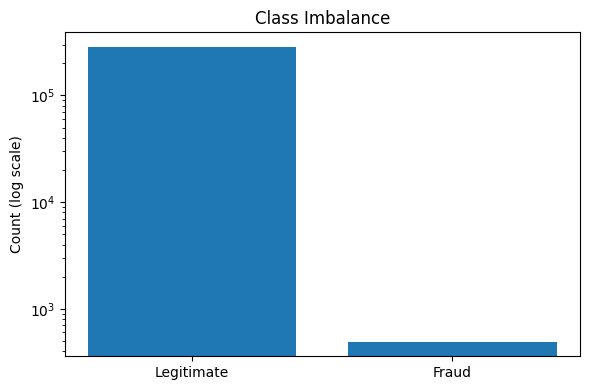

<Figure size 700x400 with 0 Axes>

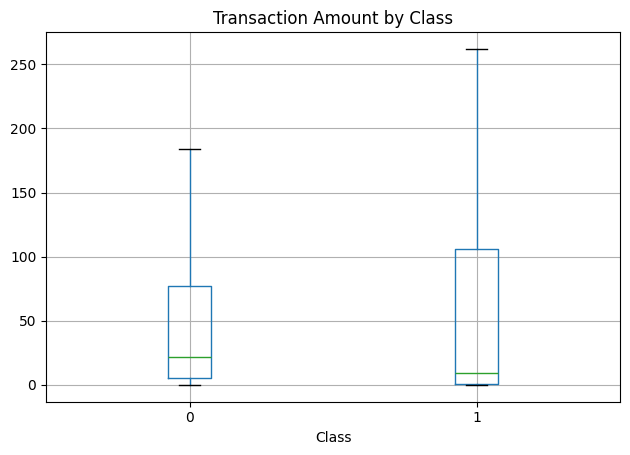

In [2]:
required = {"Time", "Amount", "Class"}
if not required.issubset(df.columns): raise ValueError(f"Expected columns: {required}")
if not set(df["Class"].dropna().unique()).issubset({0,1}): raise ValueError("Class must be 0 or 1")
print("Missing values:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
counts = df["Class"].value_counts().sort_index()
display(pd.DataFrame({"count": counts, "percentage": 100*counts/len(df)}))
print(f"Fraud rate: {100*df['Class'].mean():.4f}%")
plt.figure(figsize=(6,4))
plt.bar(["Legitimate","Fraud"], [int((df.Class==0).sum()), int((df.Class==1).sum())])
plt.yscale("log"); plt.ylabel("Count (log scale)"); plt.title("Class Imbalance")
plt.tight_layout(); plt.show()
plt.figure(figsize=(7,4))
df.boxplot(column="Amount", by="Class", showfliers=False)
plt.title("Transaction Amount by Class"); plt.suptitle("")
plt.tight_layout(); plt.show()

## 3. Chronological train / validation / test split

In [3]:
df = df.sort_values("Time").reset_index(drop=True)
n = len(df); train_end = int(n*.60); val_end = int(n*.80)
train_df, val_df, test_df = df.iloc[:train_end].copy(), df.iloc[train_end:val_end].copy(), df.iloc[val_end:].copy()
target = "Class"; features = [c for c in df.columns if c != target]
X_train, y_train = train_df[features], train_df[target]
X_val, y_val = val_df[features], val_df[target]
X_test, y_test = test_df[features], test_df[target]
for name, part in [("train",train_df),("validation",val_df),("test",test_df)]:
    print(name, "rows:",len(part),"frauds:",int(part[target].sum()),"fraud %:",round(100*part[target].mean(),4))
if any(y.nunique()<2 for y in [y_train,y_val,y_test]):
    raise ValueError("A split has only one class. Review the data and split strategy.")

train rows: 170884 frauds: 360 fraud %: 0.2107
validation rows: 56961 frauds: 57 fraud %: 0.1001
test rows: 56962 frauds: 75 fraud %: 0.1317


## 4. Define preprocessing and models

In [4]:
scaled_cols = [c for c in ["Time","Amount"] if c in features]
other_cols = [c for c in features if c not in scaled_cols]
prep = ColumnTransformer([("scale",StandardScaler(),scaled_cols),("other","passthrough",other_cols)])
models = {
 "Logistic Regression": Pipeline([("prep",prep),("model",LogisticRegression(class_weight="balanced",max_iter=1000,solver="liblinear",random_state=RANDOM_STATE))]),
 "Random Forest": Pipeline([("prep",prep),("model",RandomForestClassifier(n_estimators=120,max_depth=16,min_samples_leaf=2,class_weight="balanced_subsample",n_jobs=-1,random_state=RANDOM_STATE))])
}

## 5. Train and select threshold on validation set

In [5]:
def threshold_by_f1(y, scores):
    p,r,t = precision_recall_curve(y,scores)
    if len(t)==0: return 0.5
    f1 = 2*p[:-1]*r[:-1]/(p[:-1]+r[:-1]+1e-12)
    return float(t[int(np.nanargmax(f1))])

fitted, thresholds, val_rows = {}, {}, []
for name, model in models.items():
    print("Training",name)
    model.fit(X_train,y_train)
    scores = model.predict_proba(X_val)[:,1]
    th = threshold_by_f1(y_val,scores)
    pred = (scores>=th).astype(int)
    fitted[name] = model; thresholds[name] = th
    val_rows.append({"model":name,"threshold":th,"precision":precision_score(y_val,pred,zero_division=0),
        "recall":recall_score(y_val,pred,zero_division=0),"f1":f1_score(y_val,pred,zero_division=0),
        "average_precision":average_precision_score(y_val,scores),"roc_auc":roc_auc_score(y_val,scores)})
val_results = pd.DataFrame(val_rows).sort_values("average_precision",ascending=False)
display(val_results)
val_results.to_csv(OUT/"validation_results.csv",index=False)

Training Logistic Regression
Training Random Forest


,model,threshold,precision,recall,f1,average_precision,roc_auc
1,Random Forest,0.266317,0.955556,0.754386,0.843137,0.781277,0.931644
0,Logistic Regression,0.999977,0.891304,0.719298,0.796117,0.772441,0.970996


## 6. Evaluate on untouched test set

,model,validation_threshold,precision,recall,f1,average_precision_PR_AUC,roc_auc,TP,FP,FN,TN
1,Random Forest,0.266317,0.890625,0.760000,0.820144,0.819318,0.948998,57,7,18,56880
0,Logistic Regression,0.999977,0.925926,0.666667,0.775194,0.743704,0.982016,50,4,25,56883


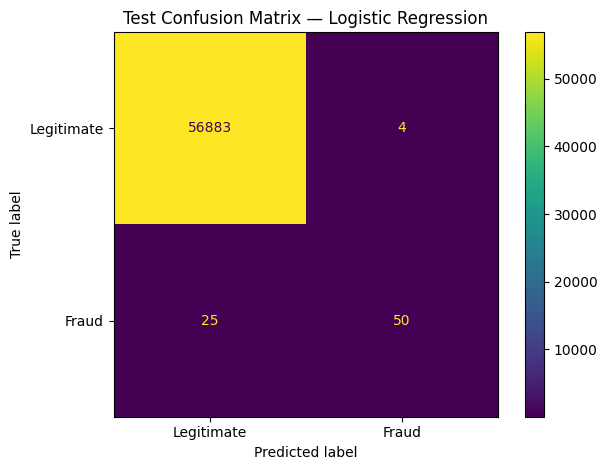

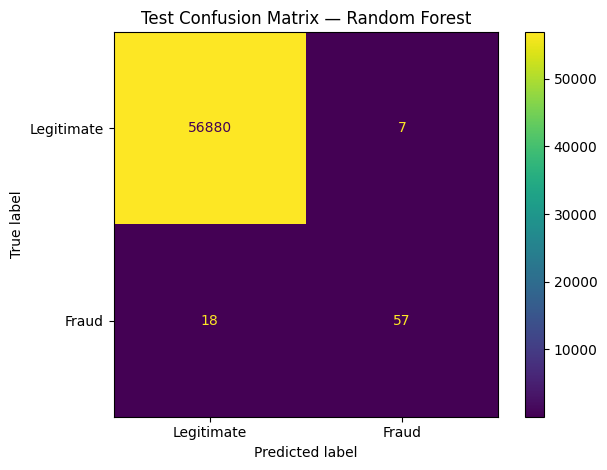

In [6]:
test_rows, scores_by_model, preds_by_model = [], {}, {}
for name, model in fitted.items():
    scores = model.predict_proba(X_test)[:,1]
    pred = (scores>=thresholds[name]).astype(int)
    scores_by_model[name] = scores; preds_by_model[name] = pred
    tn,fp,fn,tp = confusion_matrix(y_test,pred,labels=[0,1]).ravel()
    test_rows.append({"model":name,"validation_threshold":thresholds[name],
      "precision":precision_score(y_test,pred,zero_division=0),"recall":recall_score(y_test,pred,zero_division=0),
      "f1":f1_score(y_test,pred,zero_division=0),"average_precision_PR_AUC":average_precision_score(y_test,scores),
      "roc_auc":roc_auc_score(y_test,scores),"TP":tp,"FP":fp,"FN":fn,"TN":tn})
test_results = pd.DataFrame(test_rows).sort_values("average_precision_PR_AUC",ascending=False)
display(test_results)
test_results.to_csv(OUT/"test_results.csv",index=False)
for name in fitted:
    ConfusionMatrixDisplay(confusion_matrix(y_test,preds_by_model[name],labels=[0,1]),
      display_labels=["Legitimate","Fraud"]).plot(values_format="d")
    plt.title("Test Confusion Matrix — "+name); plt.tight_layout(); plt.show()

## 7. Precision–recall curves

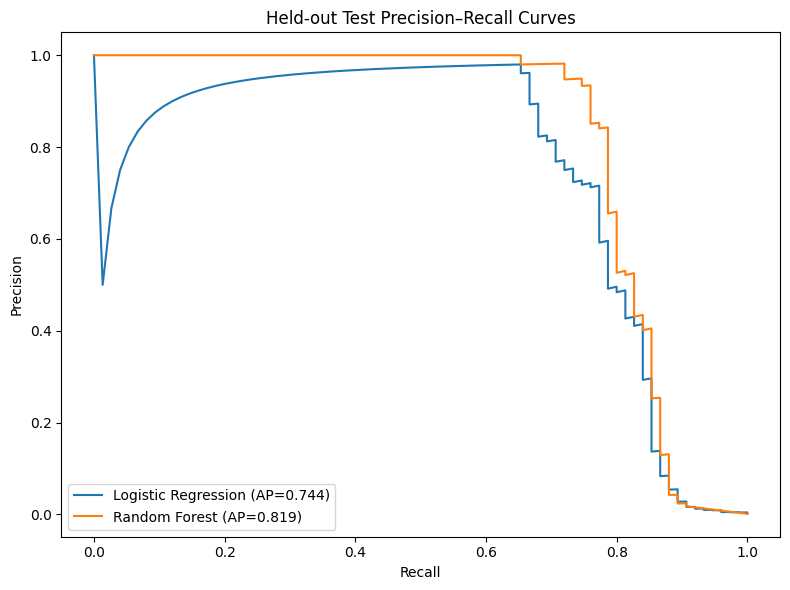

In [7]:
plt.figure(figsize=(8,6))
for name,scores in scores_by_model.items():
    p,r,_ = precision_recall_curve(y_test,scores)
    plt.plot(r,p,label=f"{name} (AP={average_precision_score(y_test,scores):.3f})")
plt.xlabel("Recall"); plt.ylabel("Precision"); plt.title("Held-out Test Precision–Recall Curves")
plt.legend(); plt.tight_layout(); plt.show()

## 8. Permutation importance for best test average-precision model

,feature,importance_mean,importance_std
14,V14,0.030208,0.007366
16,V16,0.024306,0.007366
12,V12,0.019676,0.013913
10,V10,0.009259,0.006547
11,V11,0.009259,0.006547
4,V4,0.008333,0.011785
5,V5,0.000000,0.000000
3,V3,0.000000,0.000000
2,V2,0.000000,0.000000
6,V6,0.000000,0.000000


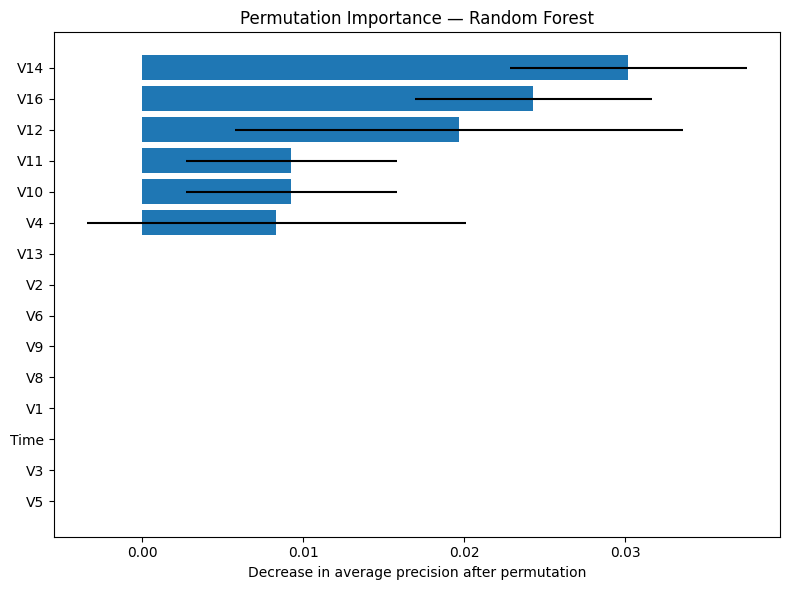

In [8]:
best_name = str(test_results.iloc[0]["model"]); best_model = fitted[best_name]
sample_n = min(5000,len(X_test))
X_imp = X_test.sample(n=sample_n,random_state=RANDOM_STATE); y_imp = y_test.loc[X_imp.index]
imp = permutation_importance(best_model,X_imp,y_imp,scoring="average_precision",n_repeats=3,random_state=RANDOM_STATE,n_jobs=-1)
importance = pd.DataFrame({"feature":features,"importance_mean":imp.importances_mean,"importance_std":imp.importances_std}).sort_values("importance_mean",ascending=False)
display(importance.head(15))
importance.to_csv(OUT/"permutation_importance.csv",index=False)
top = importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(8,6)); plt.barh(top.feature,top.importance_mean,xerr=top.importance_std)
plt.xlabel("Decrease in average precision after permutation"); plt.title("Permutation Importance — "+best_name)
plt.tight_layout(); plt.show()

## 9. Save results summary

In [9]:
summary = {"rows":int(len(df)),"frauds":int(df.Class.sum()),"fraud_rate_percent":float(100*df.Class.mean()),
 "train_rows":len(train_df),"validation_rows":len(val_df),"test_rows":len(test_df),
 "best_model_by_test_average_precision":str(test_results.iloc[0]["model"]),
 "test_results":test_results.to_dict(orient="records")}
(OUT/"experiment_summary.json").write_text(json.dumps(summary,indent=2),encoding="utf-8")
print(json.dumps(summary,indent=2))
print("Saved results to:",OUT.resolve())

{
  "rows": 284807,
  "frauds": 492,
  "fraud_rate_percent": 0.1727485630620034,
  "train_rows": 170884,
  "validation_rows": 56961,
  "test_rows": 56962,
  "best_model_by_test_average_precision": "Random Forest",
  "test_results": [
    {
      "model": "Random Forest",
      "validation_threshold": 0.26631704375776366,
      "precision": 0.890625,
      "recall": 0.76,
      "f1": 0.8201438848920863,
      "average_precision_PR_AUC": 0.8193184539141494,
      "roc_auc": 0.9489978378188338,
      "TP": 57,
      "FP": 7,
      "FN": 18,
      "TN": 56880
    },
    {
      "model": "Logistic Regression",
      "validation_threshold": 0.999976564991413,
      "precision": 0.9259259259259259,
      "recall": 0.6666666666666666,
      "f1": 0.7751937984496124,
      "average_precision_PR_AUC": 0.7437041109371159,
      "roc_auc": 0.9820163950756178,
      "TP": 50,
      "FP": 4,
      "FN": 25,
      "TN": 56883
    }
  ]
}
Saved results to: C:\Users\lakshmi\Downloads\RabTech_Task6_Digi

## 10. Discussion prompts
Use the actual results to complete `reports/whitepaper_draft.md`. Discuss the best model by test average precision, the precision–recall trade-off, false positives and false negatives, anonymized features, and the limitations of historical benchmark data. Do not retune thresholds using the test set.